In [1]:
import numpy as np

import matplotlib.pyplot as plt

# Experiment description

This supplementary experiment uses synthetic Gaussian data. The plots below
summarize its feature distributions and the missingness applied to a copy of the
data; they do not modify the Findex clustering workflow or perform imputation.
Zeros are valid values in this synthetic experiment; missing values are encoded
only as `NaN`.

# Synthetic data generation

In [2]:
seed = 42
rng = np.random.default_rng(seed)

Equicorrelation $\Sigma$ has unit variances.
$$
\Sigma = (1 - \rho)\mathbf{I}_d + \rho\mathbf{1}\mathbf{1}^T
$$
Positive definitness requires
$$
-\frac{1}{d-1} < \rho < 1
$$

In [3]:
# synthetic data generation
# generated matrix is n x d
n = 100
d = 5

mu = np.zeros(d)

I_d = np.eye(d)
rho = 0.5
# positive definitness condition
assert (-1/(d-1) < rho) and (rho < 1)

# equicorrelation Sigma has unit variances
Sigma = (1 - rho) * I_d + rho * np.ones((d, 1)) @ np.ones((d, 1)).T
# unit variances sanity check
# the formula should deliver unit variances
assert np.allclose(np.diag(Sigma), np.ones(d))

X = rng.multivariate_normal(
    mu,
    Sigma,
    size=n
)

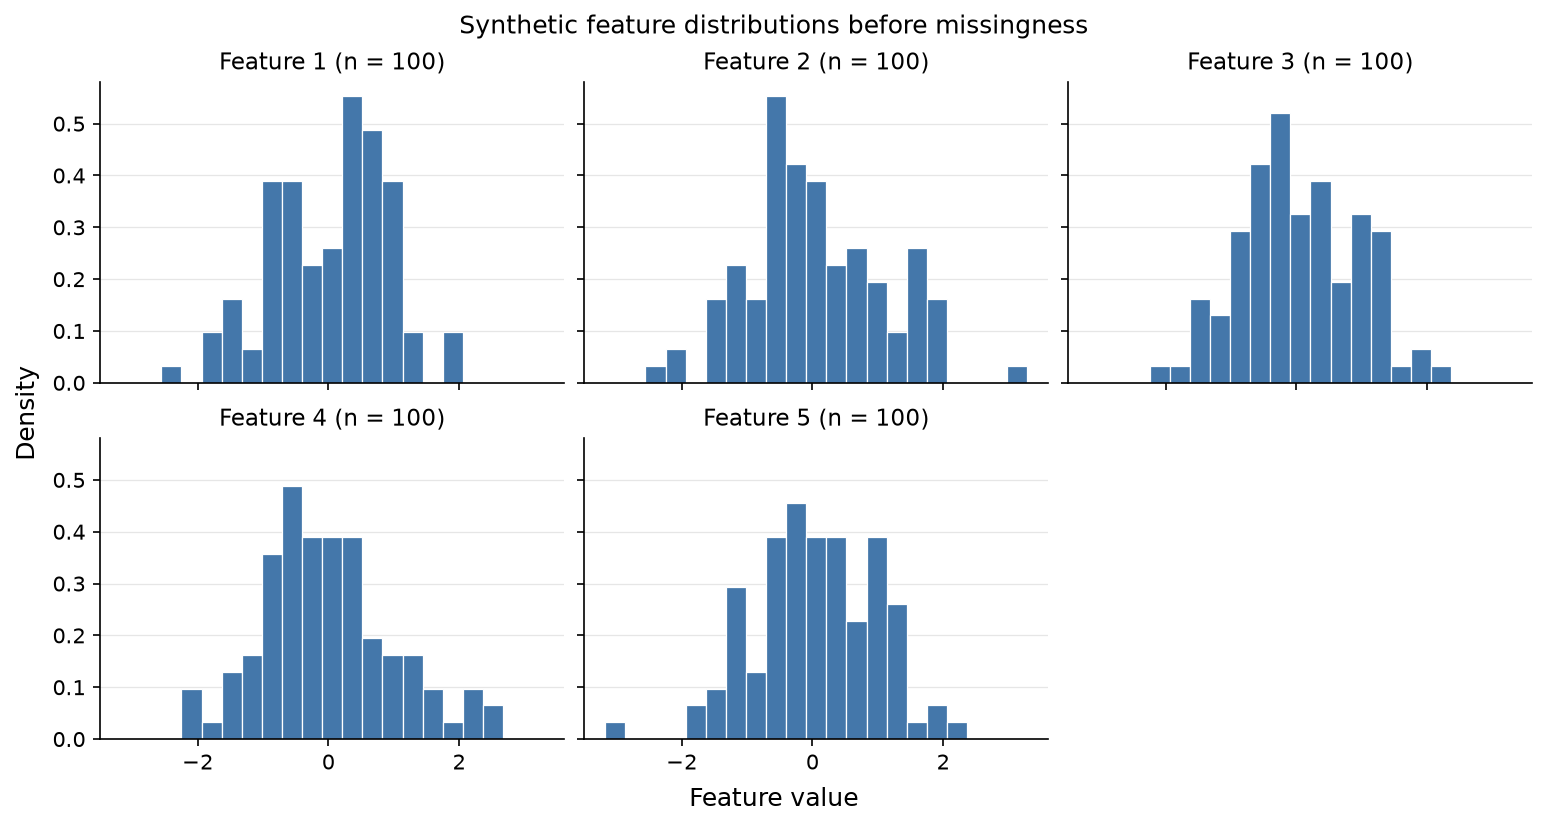

In [4]:
# Faceted histograms: common bins and axes support feature comparisons.
feature_names = [f"Feature {k + 1}" for k in range(X.shape[1])]
histogram_bins = np.histogram_bin_edges(X.ravel(), bins="fd")
plot_style = {
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}

with plt.rc_context(plot_style):
    ncols = min(3, X.shape[1])
    nrows = (X.shape[1] + ncols - 1) // ncols
    fig_histograms, axes = plt.subplots(
        nrows, ncols, figsize=(3.4 * ncols, 2.7 * nrows),
        sharex=True, sharey=True, squeeze=False, layout="constrained",
    )
    for k, ax in enumerate(axes.flat):
        if k >= X.shape[1]:
            ax.set_visible(False)
            continue
        ax.hist(
            X[:, k], bins=histogram_bins, density=True,
            color="#4477AA", edgecolor="white", linewidth=0.6,
        )
        ax.set_title(f"{feature_names[k]} (n = {X.shape[0]})")
        ax.set_axisbelow(True)
        ax.grid(axis="y", color="0.9", linewidth=0.6)
    fig_histograms.supxlabel("Feature value")
    fig_histograms.supylabel("Density")
    fig_histograms.suptitle("Synthetic feature distributions before missingness")
    plt.show()

# Applying missingness

Histograms above use the complete synthetic data, with shared Freedman–Diaconis
bins calculated from the pooled values and common axes. Each histogram has unit
area (density), allowing direct comparisons between features.

The next cell selects a fixed number of rows uniformly at random, independently
of their values, and removes the last feature in those rows. Thus `p` is the
missing fraction of the selected feature, not of the entire matrix. This is an
MCAR construction with a fixed missing count, rather than independent Bernoulli
masking of every entry.

In [9]:
# the probability of a value being missing
p = 0.3
# the missing column
miss_col = d - 1

In [10]:
X_mcar = X.copy()
# choose missing indices
missing_idx = rng.choice(n, size=round(n*p), replace=False, shuffle=False)
# apply missingness
X_mcar[missing_idx, miss_col] = np.nan

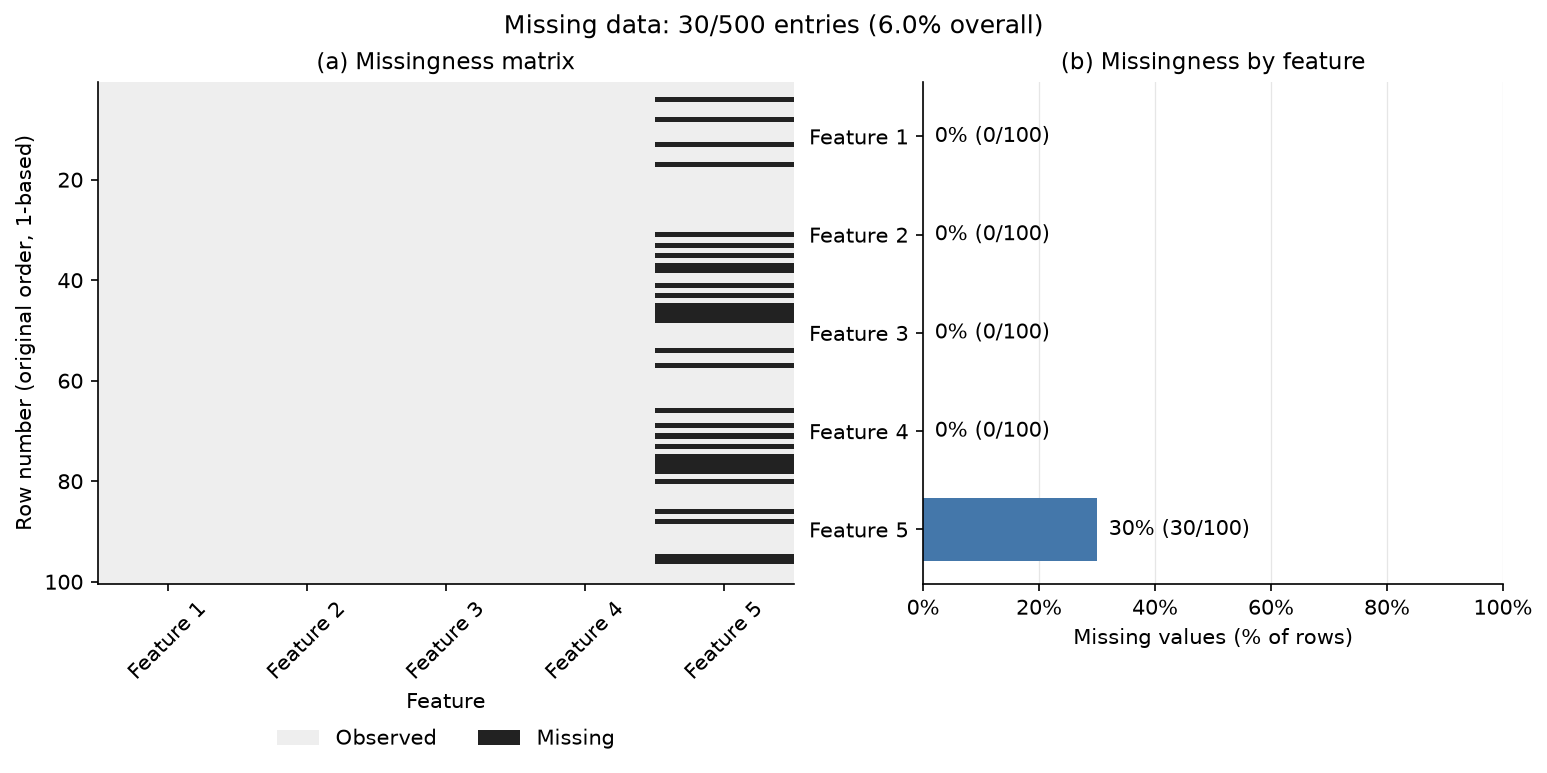

In [11]:
# Show both the locations and the marginal proportions of missing values.
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

missing_mask = np.isnan(X_mcar)
missing_counts = missing_mask.sum(axis=0)
missing_fractions = missing_mask.mean(axis=0)
missing_colors = ["#EEEEEE", "#222222"]  # Grayscale remains legible in print.
missing_cmap = ListedColormap(missing_colors)
missing_norm = BoundaryNorm([-0.5, 0.5, 1.5], missing_cmap.N)

with plt.rc_context(plot_style):
    fig_missingness, (ax_matrix, ax_bars) = plt.subplots(
        1, 2, figsize=(10.2, 5.0), gridspec_kw={"width_ratios": [1.2, 1]},
        layout="constrained",
    )
    ax_matrix.imshow(
        missing_mask, cmap=missing_cmap, norm=missing_norm,
        aspect="auto", interpolation="nearest", origin="upper",
        extent=(0.5, X_mcar.shape[1] + 0.5, X_mcar.shape[0] + 0.5, 0.5),
    )
    ax_matrix.set_xticks(np.arange(1, X_mcar.shape[1] + 1), feature_names)
    ax_matrix.tick_params(axis="x", labelrotation=45)
    ax_matrix.set_xlabel("Feature")
    ax_matrix.set_ylabel("Row number (original order, 1-based)")
    ax_matrix.set_title("(a) Missingness matrix")
    ax_matrix.legend(
        handles=[Patch(facecolor=c, label=label) for c, label in
                 zip(missing_colors, ["Observed", "Missing"])],
        loc="upper center", bbox_to_anchor=(0.5, -0.25),
        ncol=2, frameon=False,
    )

    positions = np.arange(X_mcar.shape[1])
    ax_bars.barh(positions, missing_fractions, color="#4477AA", height=0.65)
    ax_bars.set_yticks(positions, feature_names)
    ax_bars.invert_yaxis()
    ax_bars.set_xlim(0, 1)
    ax_bars.xaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax_bars.set_xlabel("Missing values (% of rows)")
    ax_bars.set_title("(b) Missingness by feature")
    ax_bars.set_axisbelow(True)
    ax_bars.grid(axis="x", color="0.9", linewidth=0.6)
    for position, fraction, count in zip(positions, missing_fractions, missing_counts):
        ax_bars.text(
            min(fraction + 0.02, 0.98), position,
            f"{fraction:.0%} ({count}/{X_mcar.shape[0]})",
            ha="left" if fraction < 0.8 else "right", va="center",
        )
    fig_missingness.suptitle(
        f"Missing data: {missing_mask.sum()}/{missing_mask.size} entries "
        f"({missing_mask.mean():.1%} overall)"
    )
    plt.show()

The binary matrix preserves the original row and feature order; the bars report
missing fractions and counts, including fully observed features. These plots
summarize where values are absent; they cannot establish MCAR from observed data
alone. Here MCAR follows from the synthetic masking mechanism.

These are conventional distribution and missing-data views; see the
[Seaborn distribution guide](https://seaborn.pydata.org/tutorial/distributions.html)
and Tierney & Cook (2023),
["Expanding Tidy Data Principles to Facilitate Missing Data Exploration, Visualization and Assessment of Imputations"](https://doi.org/10.18637/jss.v105.i07).

# Imputation

In [19]:
missing_mask = np.isnan(X_mcar[:, miss_col])

## Unconditional mean

In [28]:
ucond_mean = X_mcar[~missing_mask, miss_col].mean()
X_imp_ucond_mean = X_mcar.copy()
X_imp_ucond_mean[missing_mask, miss_col] = ucond_mean
assert np.isnan(X_imp_ucond_mean).sum() == 0

## Conditional mean

## Stochastic imputation